In [1]:
import sys
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

In [2]:
FIGURES_DIR = ROOT / "output" / "figures"

In [3]:
from src.plotting import set_plot_style, plot_trend, plot_distribution, plot_yoy_changes, compute_summary_stats

set_plot_style()

In [4]:
df = pd.read_csv('../data/clean/youth_unemp_2009_2025.csv')

# youth_unemployment

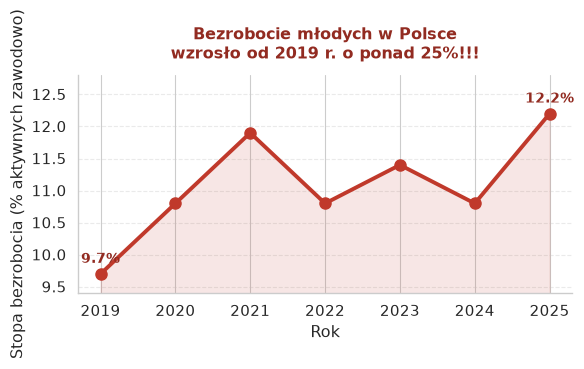

In [5]:
df_pl_manip = df[(df["country"] == "Polska") & (df["year"] >= 2019)].copy()

fig, ax = plt.subplots(figsize=(6.0, 3.5))

ax.plot(
    df_pl_manip["year"],
    df_pl_manip["value"],
    color="#C0392B",  
    marker="o",
    linewidth=2.8,
    markersize=8,
)
ax.fill_between(
    df_pl_manip["year"],
    df_pl_manip["value"],
    9.4,
    color="#C0392B",
    alpha=0.12,
)

for yr in [2019, 2025]:
    val = df_pl_manip.loc[df_pl_manip["year"] == yr, "value"].values[0]
    ax.annotate(
        f"{val:.1f}%",
        xy=(yr, val),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="#922B21",
    )

ax.set_title(
    "Bezrobocie młodych w Polsce\nwzrosło od 2019 r. o ponad 25%!!!",
    fontweight="bold",
    color="#922B21",
    pad=12,
)
ax.set_xlabel("Rok")
ax.set_ylabel("Stopa bezrobocia (% aktywnych zawodowo)")
ax.set_ylim(9.4, 12.8)  
ax.set_xticks(df_pl_manip["year"])
ax.grid(axis="y", linestyle="--", alpha=0.4)
sns.despine()
plt.tight_layout()

path_manip = FIGURES_DIR / "p2_unemp_manipulated"
fig.savefig(path_manip.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
plt.show()

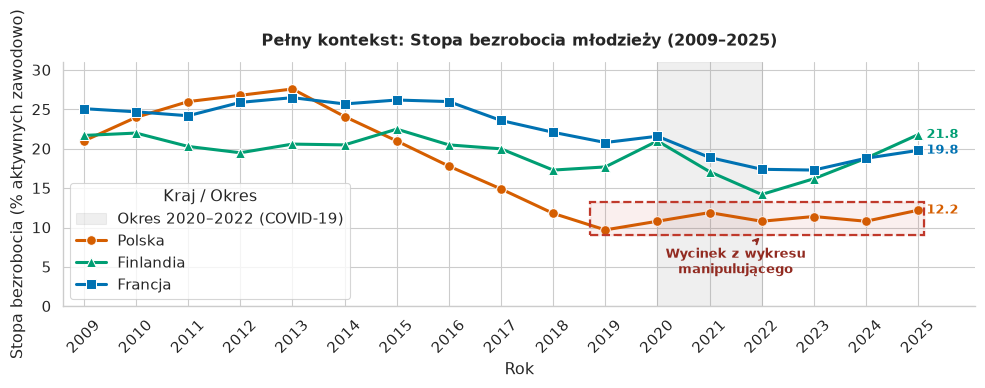

In [6]:
from matplotlib.patches import Rectangle

fig, ax = plot_trend(
    df=df,
    title="Pełny kontekst: Stopa bezrobocia młodzieży (2009–2025)",
    ylabel="Stopa bezrobocia (% aktywnych zawodowo)",
    ylim=(0, 31),
    annotate_last=True,
    save_path=None,  
)

rect = Rectangle(
    (2018.7, 9.0),   
    width=6.42,       
    height=4.2,      
    linewidth=1.8,
    edgecolor="#C0392B",
    facecolor="#C0392B",
    alpha=0.08,
    linestyle="--",
    zorder=5,
)
ax.add_patch(rect)

rect_border = Rectangle(
    (2018.7, 9.0), 6.42, 4.2,
    linewidth=1.6, edgecolor="#C0392B", facecolor="none", linestyle="--", zorder=6
)
ax.add_patch(rect_border)

ax.annotate(
    "Wycinek z wykresu\nmanipulującego",
    xy=(2022, 9.0),
    xytext=(2021.5, 4.2),
    ha="center",
    fontsize=9,
    fontweight="bold",
    color="#922B21",
    arrowprops=dict(arrowstyle="->", color="#922B21", lw=1.4),
)

path_corr = FIGURES_DIR / "p2_unemp_corrected"
fig.savefig(path_corr.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
plt.show()